# Equations

The shortest readable model of solubility is an equation. Delaney's ESOL (2004) is one line — $\log S = 0.16 - 0.63\,c\log P - 0.0062\,MW + 0.066\,RB - 0.74\,AP$ — fitted by least squares on 2,874 compounds; the features notebook found that a random forest on those same four inputs carries 0.77 bits about the tier. Symbolic regression searches the space of equations directly: PySR (Cranmer 2023) evolves expression trees over a declared set of operators, scoring each by its error and its size, and returns a Pareto front — for each size, the most accurate equation it found. The questions:

1. **How many bits can one readable line carry**, and does it beat Delaney's line on the same inputs — through better coefficients, or through a different form?
2. **Does the search rediscover ESOL's structure** (a dominant linear logP term, a size term with a negative sign), or something else?
3. **What does a few more inputs buy?** A second run on the eight descriptors the additive model ranks highest.

An equation predicts a value, not a tier distribution; the harness scores distributions. The bridge is declared here: the predicted tier distribution is a Gaussian centred on the equation's value, with standard deviation $\sigma$ chosen on the validation side, integrated over each tier's interval. $\sigma$ plays the part $\lambda$ plays for the other models — it is how an equation hedges — and $\lambda$ is still applied after it, so every model in the series is scored by the same code.

## Framework

- **Data and splits.** As in the other notebooks: unflagged votes with weight $1/n$ (flagged set aside), random and cluster 10-fold cross-validation, five learned splits. The equations are fitted to each compound's **consensus value** (the median of its unflagged votes), one row per compound, so a compound counts once however many votes it has; they are scored on every vote.
- **Inputs.** ESOL's four (MolLogP, MolWt, rotatable bonds, aromatic proportion) and the eight descriptors with the highest mean term importance in [07_additive.ipynb](07_additive.ipynb), read from its hand-off. Missing descriptor values are filled with the training median (an equation can't take a missing value).
- **Search settings, declared.** Operators $+$, $-$, $\times$, $\div$, square and $\log$; maximum expression size 20 (PySR's complexity count); 200 iterations of PySR's evolutionary loop over 31 populations of 33 expressions, with a 150-second cap per search that the timings below show never binds — a search takes a few seconds. Whether 200 iterations is enough is checked below by running ten times as many on one split. The seed is the split's index; PySR's search is multithreaded and not bit-reproducible under a seed, and the ten random splits show how much the result moves.
- **Selection.** On each random split's validation side: the equation on the front with the highest information (after choosing $\sigma$ and then $\lambda$ there). The chosen equation is then scored on the test side. Cluster and learned splits run their own searches.
- **References, through the same bridge.** Delaney's published equation (nothing fitted but $\sigma$ and $\lambda$); a refit of ESOL's form on each split's train side (same form, our coefficients), by least squares and by Huber's robust loss — the consensus values span fifteen logS units and the descriptors reach logP 68 and 5,300 Da, so a squared loss can be pulled by the tails and a loss that caps each residual's influence is the fair refit; and the random forest classifier on the same inputs (the ceiling for those inputs without the constraint of being an equation).
- **Scores.** From `scripts/aqsoldb_harness.py`: information $= H(T) - \text{log-loss}$, hard-tier accuracies; two test populations (all; 2+ unflagged votes, benchmark 0.963 bits / 76.5%).
- **Description length.** The number of nodes in the expression tree (every symbol, number and operator counts one). PySR leaves constants unfolded, so each equation is also passed through SymPy's simplifier and the shorter of the two forms is counted and shown; Delaney's line and the refit are counted the same way.

In [1]:
import itertools
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy
from pysr import PySRRegressor
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from scipy.stats import norm
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import HuberRegressor, LinearRegression

RDLogger.DisableLog("rdApp.warning")
warnings.filterwarnings("ignore", category=RuntimeWarning)  # log of a negative value inside a candidate equation
warnings.filterwarnings("ignore", message="Note: Setting `random_state`")  # stated in the framework: the search is not bit-reproducible
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from aqsoldb_harness import LAMBDAS, METRICS, calibrate, corrected_se, formatted, information, score  # noqa: E402

votes = pd.read_csv(ROOT / "data" / "aqsoldb_tiers.csv")
values = votes[votes["weight"] > 0].reset_index(drop=True)
TIERS = int(values["tier"].max()) + 1
splits = pd.read_csv(ROOT / "data" / "aqsoldb_splits.csv", index_col="InChIKey")
learned = pd.read_csv(ROOT / "data" / "aqsoldb_splits_ls.csv", index_col="InChIKey").reindex(splits.index)
features = pd.read_csv(ROOT / "data" / "aqsoldb_features.csv", index_col="InChIKey").reindex(splits.index)
importance = pd.read_csv(ROOT / "data" / "aqsoldb_ebm_importance.csv", index_col=0).iloc[:, 0]  # main effects ranked by the EBM
CV_SPLITS = [c for c in splits.columns if c.startswith("cv_") and c[3:].isdigit()]
CLUSTER_SPLITS = [c for c in splits.columns if c.startswith("cluster_") and c[8:].isdigit()]
LS_SPLITS = [c for c in learned.columns if c.startswith("ls_") and c[3:].isdigit()]
SCHEMES = {"random cross-validation": CV_SPLITS, "cluster cross-validation": CLUSTER_SPLITS, "learning to split": LS_SPLITS}
all_splits = splits.join(learned[LS_SPLITS])
assert LS_SPLITS, "run 05_learning_to_split.ipynb first"

compound = splits.index.get_indexer(values["InChIKey"])
assert (compound >= 0).all()
y, w = values["tier"].to_numpy(), values["weight"].to_numpy()
n_compounds = len(splits)
repeated = np.bincount(compound, minlength=n_compounds) > 1

# The regression target: each compound's consensus logS, one row per compound.
per_compound = values.groupby("InChIKey")["consensus"].agg(["first", "nunique"]).reindex(splits.index)
assert (per_compound["nunique"] == 1).all(), "a compound has more than one consensus value"
target = per_compound["first"].to_numpy()

# The tier boundaries, recovered from the hand-off and checked against every vote's tier.
by_tier = values.groupby("tier")["Solubility"]
CUTS = np.round((by_tier.max().to_numpy()[:-1] + by_tier.min().to_numpy()[1:]) / 2, 1)
assert (np.searchsorted(CUTS, values["Solubility"], side="right") == y).all(), "the recovered boundaries don't reproduce the tiers"

mols = [Chem.MolFromSmiles(s) for s in values.groupby("InChIKey")["SMILES"].first().reindex(splits.index)]
esol = pd.DataFrame(
    {
        "MolLogP": [Descriptors.MolLogP(m) for m in mols],
        "MolWt": [Descriptors.MolWt(m) for m in mols],
        "NumRotatableBonds": [Descriptors.NumRotatableBonds(m) for m in mols],
        "AromaticProportion": [sum(a.GetIsAromatic() for a in m.GetAtoms()) / m.GetNumHeavyAtoms() for m in mols],
    },
    index=splits.index,
)
TOP = list(importance.index[:8])
INPUTS = {"ESOL (4)": esol, "top 8 by EBM importance": features[TOP]}
print(f"{n_compounds} compounds, {len(values)} votes; tier boundaries at {CUTS} logS; top 8: {TOP}")


def calibrate_on(proba, on):
    r = on[compound]
    return calibrate(y[r], proba[compound[r]], w[r])


def evaluate(proba, on, lam):
    r = on[compound]
    return score(y[r], proba[compound[r]], w[r], lam)


def sides(split):
    side = all_splits[split].to_numpy()
    train, validation, test = side == "train", side == "validation", side == "test"
    assert train.any() and validation.any() and test.any(), f"{split}: a side has no rows"
    return train, validation, test


def test_to_train(split_list):
    return (all_splits[split_list[0]] == "test").sum() / (all_splits[split_list[0]] == "train").sum()

9946 compounds, 12013 votes; tier boundaries at [-5.3 -3.3 -1.5] logS; top 8: ['MolLogP', 'VSA_EState2', 'BCUT2D_MWLOW', 'SlogP_VSA2', 'MinPartialCharge', 'ExactMolWt', 'PEOE_VSA6', 'Kappa1']


## The bridge from a value to a tier distribution

$p(\text{tier } t \mid x) = \Phi\!\left(\frac{c_t - f(x)}{\sigma}\right) - \Phi\!\left(\frac{c_{t-1} - f(x)}{\sigma}\right)$ with $c_0 = -\infty$, $c_4 = +\infty$ and the three boundaries recovered above. $\sigma$ is chosen on the validation side from a declared grid by the information it yields (with $\lambda$ at its floor); $\lambda$ is then chosen as for every other model. A $\sigma$ well above the equation's residual spread means the equation is hedging against its own errors; a $\sigma$ near the replicate noise (about 0.5 logS) would mean the equation's errors are mostly measurement noise.

In [2]:
SIGMAS = np.round(np.arange(0.3, 2.51, 0.1), 1)
EDGES = np.concatenate([[-np.inf], CUTS, [np.inf]])


def bridge(prediction: np.ndarray, sigma: float) -> np.ndarray:
    """Tier distribution per compound: a Gaussian around the predicted value, integrated over each tier's interval."""
    return np.diff(norm.cdf((EDGES[None, :] - prediction[:, None]) / sigma), axis=1)


def choose_sigma(prediction: np.ndarray, on: np.ndarray) -> float:
    r = on[compound]
    return max(SIGMAS, key=lambda s: information(y[r], bridge(prediction, s)[compound[r]], w[r], min(LAMBDAS))[0])


def nodes(expr) -> int:
    """Description length: nodes in the expression tree."""
    return sum(1 for _ in sympy.preorder_traversal(expr))


def shortest(expr):
    """PySR leaves constants unfolded; keep whichever of its form and SymPy's simplification has fewer nodes."""
    forms = [expr, sympy.sympify(str(expr))]  # re-parsing folds 1*c and x/x
    try:
        forms.append(sympy.simplify(forms[1]))
    except Exception:  # noqa: BLE001 - a simplification that fails just keeps the other forms
        pass
    return min(forms, key=nodes)


x = sympy.symbols("MolLogP MolWt NumRotatableBonds AromaticProportion")
DELANEY = 0.16 - 0.63 * x[0] - 0.0062 * x[1] + 0.066 * x[2] - 0.74 * x[3]
delaney_prediction = sympy.lambdify(x, DELANEY)(*[esol[c].to_numpy() for c in esol.columns])
print(f"Delaney's equation: {DELANEY}  ({nodes(DELANEY)} nodes)")

Delaney's equation: -0.74*AromaticProportion - 0.63*MolLogP - 0.0062*MolWt + 0.066*NumRotatableBonds + 0.16  (14 nodes)


## The searches

One PySR search per input set per split (25 splits × 2 input sets), each with the same declared settings and a fixed time budget; the random-split searches are also where the selection happens. The table after the loop reports, for the random splits, the validation information of the chosen equation per split, its complexity and $\sigma$.

In [3]:
PYSR_SETTINGS = dict(
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["square", "log"],
    maxsize=20,
    niterations=200,  # the time budget below is what actually stops the search
    timeout_in_seconds=150,
    population_size=33,
    progress=False,
    verbosity=0,
    temp_equation_file=True,
    delete_tempfiles=True,
)


def search(inputs: str, split: str, seed: int):
    """A PySR run on the train compounds' consensus values; returns the model and the train-median fill used for missing inputs."""
    train, _, _ = sides(split)
    frame = INPUTS[inputs]
    fill = frame[train].median()
    model = PySRRegressor(random_state=seed, **PYSR_SETTINGS)
    model.fit(frame[train].fillna(fill).to_numpy(), target[train], variable_names=list(frame.columns))
    return model, fill


def front_predictions(model, inputs: str, fill) -> list[tuple[int, int, sympy.Expr, np.ndarray]]:
    """For each equation on the front: (row, nodes, sympy expression, predicted value for every compound)."""
    frame = INPUTS[inputs].fillna(fill).to_numpy()
    out = []
    for i in range(len(model.equations_)):
        expr = shortest(model.sympy(i))
        prediction = np.asarray(model.predict(frame, index=i), dtype=float).ravel()
        if np.isfinite(prediction).all():
            out.append((i, nodes(expr), expr, prediction))
    return out


def best_on_validation(candidates, validation):
    """The candidate (and its σ, λ) with the highest validation information."""
    scored = []
    for i, n, expr, prediction in candidates:
        sigma = choose_sigma(prediction, validation)
        proba = bridge(prediction, sigma)
        lam = calibrate_on(proba, validation)
        r = validation[compound]
        scored.append((information(y[r], proba[compound[r]], w[r], lam)[0], i, n, expr, prediction, sigma, lam))
    return max(scored, key=lambda s: s[0]), scored


started = time.time()
searches, fronts, chosen = {}, {}, {}
for inputs, (scheme, split_list) in itertools.product(INPUTS, SCHEMES.items()):
    for k, split in enumerate(split_list):
        train, validation, test = sides(split)
        model, fill = search(inputs, split, seed=k)
        candidates = front_predictions(model, inputs, fill)
        (info, i, n, expr, prediction, sigma, lam), scored = best_on_validation(candidates, validation)
        searches[inputs, split], fronts[inputs, split] = model, scored
        chosen[inputs, split] = {"equation": expr, "nodes": n, "σ": sigma, "λ": lam, "validation information (bits)": info, "prediction": prediction}
        print(f"{inputs:24s} {split:10s} {time.time() - started:6.0f}s  {n:2d} nodes  σ={sigma}  {info:.3f} bits  {expr}")
pd.DataFrame({(inputs, s): {k: v for k, v in chosen[inputs, s].items() if k != "prediction"} for inputs in INPUTS for s in CV_SPLITS}).T

ESOL (4)                 cv_0           11s  24 nodes  σ=1.2  0.634 bits  -log(MolWt + (AromaticProportion**2 + MolLogP**2)**2) + log(MolWt + (MolLogP - 8.39302)**4) - 4.612459


ESOL (4)                 cv_1           16s  26 nodes  σ=1.2  0.645 bits  (MolLogP + 17.62018)/(AromaticProportion + (27.68606*MolLogP - 27.68606*(MolLogP - 7.3440094)**2)/(MolWt - 17.62018) - 4.392342)


ESOL (4)                 cv_2           22s  19 nodes  σ=1.3  0.638 bits  (-3.114161*MolLogP + 0.82110655*NumRotatableBonds + 42.006954)/log(MolLogP**4 + MolWt) - 9.689769


ESOL (4)                 cv_3           28s  26 nodes  σ=1.3  0.610 bits  -44.072002/(-AromaticProportion + (MolLogP - 12.440044)**4/log(4*MolLogP**2 + MolWt)**4 + log(MolWt))


ESOL (4)                 cv_4           34s  22 nodes  σ=1.4  0.604 bits  -43.84434/(-AromaticProportion + (12.149605 - MolLogP)**4/log(MolWt)**4 + log(MolWt))


ESOL (4)                 cv_5           40s  22 nodes  σ=1.3  0.582 bits  -AromaticProportion - 0.13977909001688*MolLogP - 0.97835195*log(MolLogP**2*(MolLogP + 7.8038483)**2 + MolWt) + 4.3280470533373


... (41 outputs left out)

top 8 by EBM importance  ls_2          287s  19 nodes  σ=0.9  0.870 bits  -2.403264*MolLogP*log(ExactMolWt)/(BCUT2D_MWLOW + Kappa1 - MolLogP) - 1.4721417*log(ExactMolWt) + 6.50564


top 8 by EBM importance  ls_3          294s  18 nodes  σ=1.0  0.906 bits  -1.9787151*MolLogP + (MolLogP - 4.7520566)*log(log(Kappa1 + (MolLogP - 2.218967)**2)) + 3.77036968696801


top 8 by EBM importance  ls_4          299s  19 nodes  σ=0.9  0.989 bits  -3.4261727 + (-12.232974054963*MolLogP - 0.464420684888615*VSA_EState2 + 37.6346296901376)/(Kappa1 - 1.2737771*MolLogP + 4.4826674)


equation  \
ESOL (4)                cv_0  -log(MolWt + (AromaticProportion**2 + MolLogP*...   
                        cv_1  (MolLogP + 17.62018)/(AromaticProportion + (27...   
                        cv_2  (-3.114161*MolLogP + 0.82110655*NumRotatableBo...   
                        cv_3  -44.072002/(-AromaticProportion + (MolLogP - 1...   
                        cv_4  -43.84434/(-AromaticProportion + (12.149605 - ...   
                        cv_5  -AromaticProportion - 0.13977909001688*MolLogP...   
                        cv_6  -AromaticProportion - log(((MolLogP + log(MolL...   
                        cv_7  -log(MolWt + ((MolLogP + 2.67945)**2 - 10.4115...   
                        cv_8  -(AromaticProportion + MolLogP)/((MolLogP - 5....   
                        cv_9  -AromaticProportion - 36.4056683625641*(MolLog...   
top 8 by EBM importance cv_0  (Kappa1 + log(ExactMolWt))*log(ExactMolWt + VS...   
                        cv_1  -(MinPartialCharge + 0.4410355)**2 - 49.368317...   
                        cv_2  -6.132058*(log(log((2*MolLogP + log(Kappa1 + M...   
                        cv_3  -log(ExactMolWt + MolLogP**2*(0.57228644516090...   
                        cv_4  -0.6052816*log(Kappa1 + (MolLogP + log(0.27376...   
                        cv_5  -1.1373018*log((MolLogP + log((0.13372594*Kapp...   
                        cv_6  -MinPartialCharge**2 - MinPartialCharge - 8.75...   
                        cv_7  -0.26065964*MolLogP - 0.26065964*log(Kappa1**2...   
                        cv_8  log(0.00031555517 + 226.761072553744*(MolLogP ...   
                        cv_9  -MolLogP + (0.13089794*MolLogP - 0.78377026)*l...   

                             nodes    σ     λ validation information (bits)  
ESOL (4)                cv_0    24  1.2  0.05                      0.633771  
                        cv_1    26  1.2  0.05                      0.645033  
                        cv_2    19  1.3  0.05                      0.637669  
                        cv_3    26  1.3   0.1                      0.610131  
                        cv_4    22  1.4  0.05                      0.603586  
                        cv_5    22  1.3  0.05                      0.582401  
                        cv_6    23  1.4  0.05                      0.571335  
                        cv_7    24  1.3  0.05                      0.639751  
                        cv_8    29  1.2  0.05                      0.649224  
                        cv_9    22  1.2  0.05                      0.667114  
top 8 by EBM importance cv_0    21  1.2  0.05                      0.660259  
                        cv_1    27  1.3  0.05                      0.635676  
                        cv_2    24  1.4  0.05                       0.61368  
                        cv_3    26  1.3   0.1                      0.610618  
                        cv_4    19  1.5  0.05                      0.536537  
                        cv_5    21  1.3  0.05                      0.586662  
                        cv_6    28  1.3  0.05                      0.638342  
                        cv_7    20  1.3  0.05                      0.581077  
                        cv_8    22  1.2  0.05                      0.589805  
                        cv_9    22  1.2  0.05                      0.653856

### Is 200 iterations enough?

The same search on the first random split with ten times the iterations, for each input set, against the 200-iteration result above: the information of the chosen equation on the validation side (where it was chosen) and on the test side.

In [4]:
LONGER = 2000
rows = []
for inputs in INPUTS:
    train, validation, test = sides(CV_SPLITS[0])
    for iterations in (PYSR_SETTINGS["niterations"], LONGER):
        if iterations == PYSR_SETTINGS["niterations"]:
            c = chosen[inputs, CV_SPLITS[0]]
            info, n, expr, prediction, sigma, lam, seconds = c["validation information (bits)"], c["nodes"], c["equation"], c["prediction"], c["σ"], c["λ"], np.nan
        else:
            t0 = time.time()
            model = PySRRegressor(random_state=0, **{**PYSR_SETTINGS, "niterations": iterations, "timeout_in_seconds": 1800})
            frame = INPUTS[inputs]
            fill = frame[train].median()
            model.fit(frame[train].fillna(fill).to_numpy(), target[train], variable_names=list(frame.columns))
            (info, i, n, expr, prediction, sigma, lam), _ = best_on_validation(front_predictions(model, inputs, fill), validation)
            seconds = time.time() - t0
        rows.append({"inputs": inputs, "iterations": iterations, "seconds": seconds, "nodes": n, "σ": sigma,
                     "validation information (bits)": info, "test information (bits)": evaluate(bridge(prediction, sigma), test, lam)["information (bits)"],
                     "equation": str(sympy.N(expr, 3))})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index(["inputs", "iterations"]).round(3)

seconds  nodes    σ  \
inputs                  iterations                        
ESOL (4)                200             NaN     24  1.2   
                        2000         55.786     23  1.2   
top 8 by EBM importance 200             NaN     21  1.2   
                        2000         67.313     20  1.2   

                                    validation information (bits)  \
inputs                  iterations                                  
ESOL (4)                200                                 0.634   
                        2000                                0.636   
top 8 by EBM importance 200                                 0.660   
                        2000                                0.652   

                                    test information (bits)  \
inputs                  iterations                            
ESOL (4)                200                           0.642   
                        2000                          0.637   
top 8 by EBM importance 200                           0.654   
                        2000                          0.663   

                                                                                                                                              equation  
inputs                  iterations                                                                                                                      
ESOL (4)                200                         -log(MolWt + (AromaticProportion**2 + MolLogP**2)**2) + log(MolWt + (MolLogP - 8.39302)**4) - 4.61  
                        2000        log((NumRotatableBonds + (MolLogP - 7.3451443)**2 + 0.73448896)/(MolWt + ((MolLogP + 2.674096)**2 - 9.947706)**2))  
top 8 by EBM importance 200                            (Kappa1 + log(ExactMolWt))*log(ExactMolWt + VSA_EState2)/(-Kappa1 + 1.54*MolLogP - 6.29) + 3.57  
                        2000                                 -log(ExactMolWt + MolLogP**4) + log(BCUT2D_MWLOW*Kappa1 + (MolLogP - 7.9401655)**4) - 4.3

### The front on the random splits

Validation information against equation size for every equation on PySR's front, one colour-shade per random split, for each input set: the points are the equations, the line through each split is the best information at or below each size (PySR's front trades loss for size; node count is not monotone in its complexity measure, so the line is the running best). Where the lines flatten, more nodes buy nothing a reader could use.

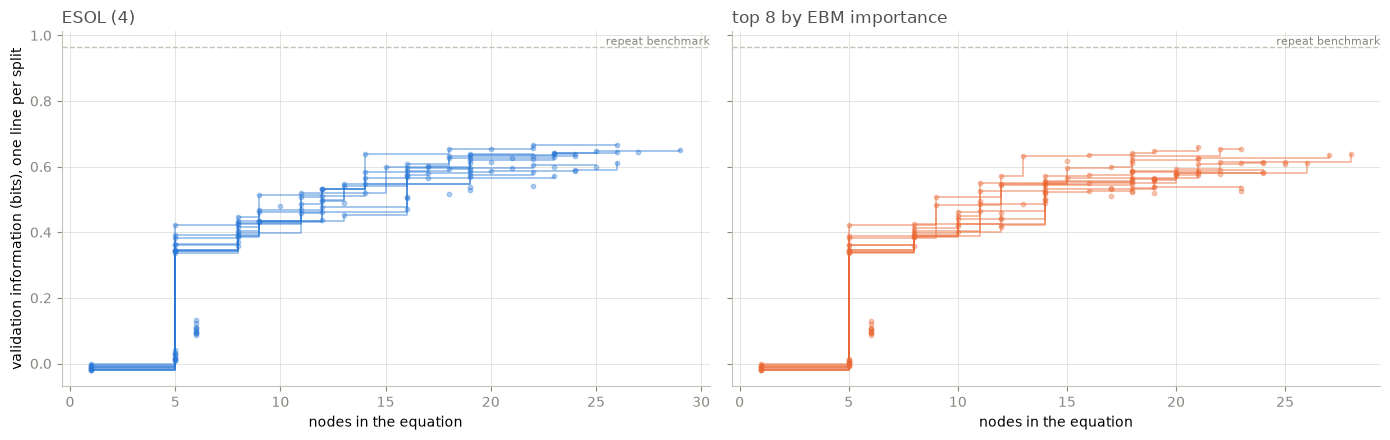

In [5]:
INK, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLORS = ["#2a78d6", "#eb6834"]


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (inputs, color) in zip(axes, zip(INPUTS, COLORS)):
    for split in CV_SPLITS:
        pts = sorted((n, info) for info, i, n, expr, prediction, sigma, lam in fronts[inputs, split])
        ax.scatter([p[0] for p in pts], [p[1] for p in pts], color=color, alpha=0.35, s=10)
        ax.step([p[0] for p in pts], np.maximum.accumulate([p[1] for p in pts]), where="post", color=color, alpha=0.5, lw=1.2)
    ax.axhline(0.963, color=AXIS, lw=1, ls="--")
    ax.text(ax.get_xlim()[1], 0.963, " repeat benchmark", color=MUTED, fontsize=8, va="bottom", ha="right")
    ax.set_title(inputs, loc="left", color=INK)
    ax.set_xlabel("nodes in the equation")
    style(ax)
axes[0].set_ylabel("validation information (bits), one line per split")
fig.tight_layout()

## Against the references, on three kinds of split

Every row goes through the same bridge and the same calibration on the validation side. "Delaney's equation" fits nothing but $\sigma$ and $\lambda$; the two refits fit its five coefficients on each train side, by least squares and by Huber's loss; "random forest" is the features notebook's classifier on the same inputs. After the table: the coefficients the refits found, beside Delaney's.

In [6]:
RF_SETTINGS = dict(n_estimators=500, n_jobs=-1, random_state=0)
SUBSETS = {"all test compounds": np.ones(n_compounds, bool), "test compounds with 2+ unflagged votes": repeated}


def refit(inputs: str, train: np.ndarray, estimator):
    """ESOL's form (a linear combination of the inputs) with coefficients fitted on the train side by the given estimator."""
    frame = INPUTS[inputs]
    fill = frame[train].median()
    model = estimator.fit(frame[train].fillna(fill), target[train])
    expr = shortest(model.intercept_ + sum(float(c) * sympy.Symbol(name) for c, name in zip(model.coef_, frame.columns)))
    coefficients = {**dict(zip(frame.columns, model.coef_)), "intercept": model.intercept_}
    return model.predict(frame.fillna(fill)), nodes(expr), coefficients


def forest(inputs: str, train: np.ndarray):
    rows = train[compound]
    frame = INPUTS[inputs].to_numpy()
    model = RandomForestClassifier(**RF_SETTINGS).fit(frame[compound[rows]], y[rows], sample_weight=w[rows])
    assert list(model.classes_) == list(range(TIERS))
    return model.predict_proba(frame), sum(t.tree_.n_leaves for t in model.estimators_) * TIERS


rows, lengths, coefficients, INPUTS_OF = [], {}, {}, {}
for scheme, split_list in SCHEMES.items():
    for split in split_list:
        train, validation, test = sides(split)
        predictors = {"Delaney's equation (published)": (delaney_prediction, nodes(DELANEY), "ESOL (4)")}
        for label, estimator in [("least squares", LinearRegression()), ("Huber", HuberRegressor(max_iter=1000))]:
            prediction, length, coef = refit("ESOL (4)", train, estimator)
            predictors[f"{label} refit of ESOL's form"] = (prediction, length, "ESOL (4)")
            if scheme == "random cross-validation":
                coefficients.setdefault(label, []).append(coef)
        for inputs in INPUTS:
            predictors[f"PySR, {inputs}"] = (chosen[inputs, split]["prediction"], chosen[inputs, split]["nodes"], inputs)
        for inputs in INPUTS:
            predictors[f"random forest, {inputs}"] = (*forest(inputs, train), inputs)
        for name, (prediction, length, inputs) in predictors.items():
            INPUTS_OF[name] = inputs
            if prediction.ndim == 1:
                sigma = choose_sigma(prediction, validation)
                proba = bridge(prediction, sigma)
            else:
                sigma, proba = np.nan, prediction
            lam = calibrate_on(proba, validation)
            lengths.setdefault(name, []).append(length)
            for subset, mask in SUBSETS.items():
                rows.append({"predictor": name, "scheme": scheme, "split": split, "subset": subset, "σ": sigma, "λ": lam, **evaluate(proba, test & mask, lam)})
held_out = pd.DataFrame(rows)
PREDICTORS = list(dict.fromkeys(held_out["predictor"]))

tables, means = {}, {}
for name in PREDICTORS:
    blocks = {}
    for scheme, split_list in SCHEMES.items():
        d = held_out[(held_out["predictor"] == name) & (held_out["scheme"] == scheme)]
        by = d.groupby("subset", sort=False)[list(METRICS)]
        if scheme == "learning to split":
            spread = by.std()
            blocks[f"{scheme} (mean ± SD)"] = formatted(by.mean()) + " ± " + formatted(spread)
        else:
            spread = by.apply(lambda g: g.apply(corrected_se, n_splits=len(split_list), test_to_train=test_to_train(split_list)))
            blocks[f"{scheme} (mean ± SE)"] = formatted(by.mean()) + " ± " + formatted(spread)
        for subset in SUBSETS:
            means[name, scheme, subset] = (by.mean().loc[subset, "information (bits)"], spread.loc[subset, "information (bits)"])
    tables[name] = pd.concat(blocks, names=["split", "subset"])
print("σ chosen (median over random splits):", held_out[held_out["scheme"] == "random cross-validation"].groupby("predictor", sort=False)["σ"].median().round(2).to_dict())
delaney_coefficients = {"MolLogP": -0.63, "MolWt": -0.0062, "NumRotatableBonds": 0.066, "AromaticProportion": -0.74, "intercept": 0.16}
display(pd.DataFrame({"Delaney (published)": delaney_coefficients, **{f"{k} refit (mean over random splits)": pd.DataFrame(v).mean() for k, v in coefficients.items()}}).round(4))
pd.concat(tables, names=["predictor"])[["information (bits)", "accuracy: same tier (%)", "1 tier off (%)", "2+ tiers off (%)"]]

σ chosen (median over random splits): {"Delaney's equation (published)": 1.35, "least squares refit of ESOL's form": 1.5, "Huber refit of ESOL's form": 1.4, 'PySR, ESOL (4)': 1.3, 'PySR, top 8 by EBM importance': 1.3, 'random forest, ESOL (4)': nan, 'random forest, top 8 by EBM importance': nan}


,Delaney (published),least squares refit (mean over random splits),Huber refit (mean over random splits)
MolLogP,-0.6300,-0.3873,-0.5350
MolWt,-0.0062,-0.0039,-0.0063
NumRotatableBonds,0.0660,0.0746,0.0945
AromaticProportion,-0.7400,-0.7995,-0.6522
intercept,0.1600,-1.1274,-0.2831


information (bits)  \
predictor                              split                                subset                                                      
Delaney's equation (published)         random cross-validation (mean ± SE)  all test compounds                          0.595 ± 0.018   
                                                                            test compounds with 2+ unflagged votes      0.551 ± 0.037   
                                       cluster cross-validation (mean ± SE) all test compounds                          0.588 ± 0.027   
                                                                            test compounds with 2+ unflagged votes      0.542 ± 0.040   
                                       learning to split (mean ± SD)        all test compounds                         -0.451 ± 0.111   
                                                                            test compounds with 2+ unflagged votes     -0.386 ± 0.180   
least squares refit of ESOL's form     random cross-validation (mean ± SE)  all test compounds                          0.451 ± 0.014   
                                                                            test compounds with 2+ unflagged votes      0.393 ± 0.036   
                                       cluster cross-validation (mean ± SE) all test compounds                          0.436 ± 0.022   
                                                                            test compounds with 2+ unflagged votes      0.374 ± 0.046   
                                       learning to split (mean ± SD)        all test compounds                         -0.445 ± 0.140   
                                                                            test compounds with 2+ unflagged votes     -0.419 ± 0.198   
Huber refit of ESOL's form             random cross-validation (mean ± SE)  all test compounds                          0.555 ± 0.018   
                                                                            test compounds with 2+ unflagged votes      0.513 ± 0.036   
                                       cluster cross-validation (mean ± SE) all test compounds                          0.544 ± 0.027   
                                                                            test compounds with 2+ unflagged votes      0.504 ± 0.043   
                                       learning to split (mean ± SD)        all test compounds                         -0.514 ± 0.105   
                                                                            test compounds with 2+ unflagged votes     -0.408 ± 0.177   
PySR, ESOL (4)                         random cross-validation (mean ± SE)  all test compounds                          0.619 ± 0.018   
                                                                            test compounds with 2+ unflagged votes      0.585 ± 0.041   
                                       cluster cross-validation (mean ± SE) all test compounds                          0.594 ± 0.036   
                                                                            test compounds with 2+ unflagged votes      0.570 ± 0.033   
                                       learning to split (mean ± SD)        all test compounds                         -0.536 ± 0.195   
                                                                            test compounds with 2+ unflagged votes     -0.444 ± 0.260   
PySR, top 8 by EBM importance          random cross-validation (mean ± SE)  all test compounds                          0.599 ± 0.018   
                                                                            test compounds with 2+ unflagged votes      0.571 ± 0.040   
                                       cluster cross-validation (mean ± SE) all test compounds                          0.621 ± 0.032   
                                                                            test compounds with 2+ unflagged votes      0.601 ± 0.025   
     

**Reading the table.** Three things stand out.

*Delaney's published line beats a least-squares refit of its own form on this data* — 0.595 bits against 0.451, 63.0% against 57.0% in the same tier — and the coefficient table says why. Least squares pulled the logP slope from −0.63 to −0.39 and the size slope from −0.0062 to −0.0039 while pushing the intercept to −1.1: the squared loss has gone after the tails of a target that spans fifteen logS units, at the expense of the bulk where the tier boundaries sit. Huber's loss, which caps each residual's pull, brings the slopes back to within 0.1 of Delaney's (−0.535 logP, −0.0063 MolWt, −0.65 aromatic proportion) and recovers 0.555 bits. The 0.04 bits still between the Huber refit and Delaney are the difference between his 2,874 compounds and this set's bulk; his line is not optimal here, but it is closer to the robust fit than to the least-squares one.

*The search beats Delaney by a little and the forest by a lot.* PySR's chosen equations carry 0.619 ± 0.018 bits on random splits and 0.594 on cluster splits against Delaney's 0.595 and 0.588 — a gain within one standard error, bought with 22 nodes instead of 14 — while the forest on the same four inputs carries 0.769 and 0.725. The eight descriptors the additive model ranks highest give the search nothing on random splits (0.599) and 0.03 bits on cluster splits (0.621 against 0.594), where the forest on those eight inputs reaches 0.896. An equation of twenty nodes is an equation of three or four variables whatever the inputs offered, and about 0.6 bits is what that buys: the gap to the forest is not a failure of the search (ten times the iterations changed the chosen equation's information by less than 0.01 bits either way) but the ceiling of the form.

*Equations hedge.* Every equation chose σ between 1.2 and 1.5 logS, roughly three times the replicate noise: the Gaussian bridge is absorbing the equation's own error, not the measurement's. Their hard-tier accuracies sit at 62–63%, with 32–33% one tier off and 5% two or more — the same error profile as Delaney's line. On the learned splits every equation is less negative than the forests (−0.45 to −0.54 bits against −0.80 and −1.26): a smooth function of four variables extrapolates to unfamiliar chemistry with less false confidence than a vote over leaves.

## Description length, and the equations themselves

The mean node count per model over the random splits, written with the held-out information to `data/aqsoldb_front_equations.csv` for the front notebook. Then the chosen equations of the ten random splits for each input set, to read for recurring structure: which variables appear, with which sign, and whether any nonlinearity survives.

In [7]:
length = pd.Series({name: np.mean(v) for name, v in lengths.items()}, name="numbers to write it down (nodes, or leaves × tiers)")
front = pd.DataFrame(
    [{"model": name, "family": "random forest" if name.startswith("random forest") else "equation", "inputs": INPUTS_OF[name],
      "scheme": scheme, "subset": subset, "information (bits)": means[name, scheme, subset][0], "spread": means[name, scheme, subset][1],
      "numbers to write it down": length[name], "readable": not name.startswith("random forest")}
     for name in PREDICTORS for scheme in SCHEMES for subset in SUBSETS]
)
front.to_csv(ROOT / "data" / "aqsoldb_front_equations.csv", index=False)
display(length.round(0).to_frame())

pd.set_option("display.max_colwidth", 200)
equations = pd.DataFrame(
    [{"inputs": inputs, "split": s, "nodes": chosen[inputs, s]["nodes"], "σ": chosen[inputs, s]["σ"],
      "equation": str(sympy.N(chosen[inputs, s]["equation"], 3))} for inputs in INPUTS for s in CV_SPLITS]
).set_index(["inputs", "split"])
equations

,"numbers to write it down (nodes, or leaves × tiers)"
Delaney's equation (published),14.0
least squares refit of ESOL's form,14.0
Huber refit of ESOL's form,14.0
"PySR, ESOL (4)",22.0
"PySR, top 8 by EBM importance",22.0
"random forest, ESOL (4)",3919524.0
"random forest, top 8 by EBM importance",3411705.0


nodes    σ  \
inputs                  split               
ESOL (4)                cv_0      24  1.2   
                        cv_1      26  1.2   
                        cv_2      19  1.3   
                        cv_3      26  1.3   
                        cv_4      22  1.4   
                        cv_5      22  1.3   
                        cv_6      23  1.4   
                        cv_7      24  1.3   
                        cv_8      29  1.2   
                        cv_9      22  1.2   
top 8 by EBM importance cv_0      21  1.2   
                        cv_1      27  1.3   
                        cv_2      24  1.4   
                        cv_3      26  1.3   
                        cv_4      19  1.5   
                        cv_5      21  1.3   
                        cv_6      28  1.3   
                        cv_7      20  1.3   
                        cv_8      22  1.2   
                        cv_9      22  1.2   

                                                                                                                                             equation  
inputs                  split                                                                                                                          
ESOL (4)                cv_0                       -log(MolWt + (AromaticProportion**2 + MolLogP**2)**2) + log(MolWt + (MolLogP - 8.39302)**4) - 4.61  
                        cv_1                  (MolLogP + 17.6)/(AromaticProportion + (27.7*MolLogP - 27.7*(MolLogP - 7.34)**2)/(MolWt - 17.6) - 4.39)  
                        cv_2                                          (-3.11*MolLogP + 0.821*NumRotatableBonds + 42.0)/log(MolLogP**4 + MolWt) - 9.69  
                        cv_3                              -44.1/(-AromaticProportion + (MolLogP - 12.4)**4/log(4*MolLogP**2 + MolWt)**4 + log(MolWt))  
                        cv_4                                             -43.8/(-AromaticProportion + (12.2 - MolLogP)**4/log(MolWt)**4 + log(MolWt))  
                        cv_5                       -AromaticProportion - 0.14*MolLogP - 0.978*log(MolLogP**2*(MolLogP + 7.8038483)**2 + MolWt) + 4.33  
                        cv_6       -AromaticProportion - log(((MolLogP + log(MolLogP**4 + NumRotatableBonds + 0.017024238))**2 + 16.823637)**2) + 5.1  
                        cv_7    -log(MolWt + ((MolLogP + 2.67945)**2 - 10.411533)**2) + log(NumRotatableBonds + (MolLogP - 7.1019382)**2 + 1.3423002)  
                        cv_8       -(AromaticProportion + MolLogP)/((MolLogP - 5.92)**2/log(MolWt)**2 + 1.39) - log(MolWt - NumRotatableBonds) + 4.05  
                        cv_9                                  -AromaticProportion - 36.4*(MolLogP - 3.69)/((MolLogP - 4.2)**2 + log(MolWt)**2) - 3.91  
top 8 by EBM importance cv_0                          (Kappa1 + log(ExactMolWt))*log(ExactMolWt + VSA_EState2)/(-Kappa1 + 1.54*MolLogP - 6.29) + 3.57  
                        cv_1                          -(MinPartialCharge + 0.441)**2 - 49.4/((MolLogP - 12.6)**4/log(ExactMolWt)**4 + log(Kappa1**2))  
                        cv_2                                     -6.13*(log(log((2*MolLogP + log(Kappa1 + MolLogP**2)**2)**2 + 3.705752)) - 0.916)**2  
                        cv_3   -log(ExactMolWt + MolLogP**2*(0.572286445160909*MolLogP + log(ExactMolWt))**2) + log((MolLogP - 7.388221)**2 + 3.0176)  
                        cv_4                                      -0.605*log(Kappa1 + (MolLogP + log(0.27376377275536*MolLogP**2 + 1.0464488)**2)**4)  
                        cv_5                               -1.14*log((MolLogP + log((0.13372594*Kappa1 + 0.020445913*MolLogP**4)**2))**2 + 1.4558215)  
                        cv_6                 -MinPartialCharge**2 - MinPartialCharge - 8.76 + 15.3/(1.74 + log(ExactMolWt**2)**4/(MolLogP - 13.4)**4)  
                        cv_7                                         -0.261*MolLogP - 0.261*log(Kappa1**2 + ((MolLogP + 1.3980043)**2 - 4.633602)**4)  


### Which variables recur?

For each input set: in how many of the ten random-split equations each variable appears, and the sign of $\partial f / \partial x$ at the median compound (a crude reading of direction; for a term like $\log$ or a ratio the sign can change across the range).

In [8]:
rows = []
for inputs in INPUTS:
    frame = INPUTS[inputs]
    median = {sympy.Symbol(c): float(frame[c].median()) for c in frame.columns}
    for c in frame.columns:
        sym = sympy.Symbol(c)
        present = [chosen[inputs, s]["equation"] for s in CV_SPLITS if sym in chosen[inputs, s]["equation"].free_symbols]
        slopes = [float(sympy.diff(e, sym).subs(median)) for e in present]
        rows.append({"inputs": inputs, "variable": c, "equations it appears in (of 10)": len(present),
                     "slope at the median: negative": sum(s < 0 for s in slopes), "positive": sum(s > 0 for s in slopes)})
pd.DataFrame(rows).set_index(["inputs", "variable"])

equations it appears in (of 10)  \
inputs                  variable                                              
ESOL (4)                MolLogP                                          10   
                        MolWt                                             9   
                        NumRotatableBonds                                 4   
                        AromaticProportion                                8   
top 8 by EBM importance MolLogP                                          10   
                        VSA_EState2                                       1   
                        BCUT2D_MWLOW                                      0   
                        SlogP_VSA2                                        0   
                        MinPartialCharge                                  2   
                        ExactMolWt                                        5   
                        PEOE_VSA6                                         0   
                        Kappa1                                            7   

                                            slope at the median: negative  \
inputs                  variable                                            
ESOL (4)                MolLogP                                        10   
                        MolWt                                           9   
                        NumRotatableBonds                               1   
                        AromaticProportion                              8   
top 8 by EBM importance MolLogP                                        10   
                        VSA_EState2                                     1   
                        BCUT2D_MWLOW                                    0   
                        SlogP_VSA2                                      0   
                        MinPartialCharge                                2   
                        ExactMolWt                                      5   
                        PEOE_VSA6                                       0   
                        Kappa1                                          5   

                                            positive  
inputs                  variable                      
ESOL (4)                MolLogP                    0  
                        MolWt                      0  
                        NumRotatableBonds          3  
                        AromaticProportion         0  
top 8 by EBM importance MolLogP                    0  
                        VSA_EState2                0  
                        BCUT2D_MWLOW               0  
                        SlogP_VSA2                 0  
                        MinPartialCharge           0  
                        ExactMolWt                 0  
                        PEOE_VSA6                  0  
                        Kappa1                     2

## Reading

1. **How many bits can one readable line carry?** About 0.6 — 0.619 ± 0.018 on random splits and 0.594 on cluster splits for PySR's chosen equations of about 22 nodes, against 0.595 and 0.588 for Delaney's 14-node line and 0.769 / 0.725 for a random forest on the same four inputs. The search beats Delaney's line by less than one standard error and does so by changing its form, not its coefficients: no chosen equation is linear in logP. A fair refit of Delaney's form (Huber loss) lands at 0.555 bits with slopes within 0.1 of his; least squares, pulled by the tails of a target spanning fifteen logS units, lands at 0.451 — the one time in this series the published coefficients beat a refit on the data at hand, and the reason is the loss, not the data.

2. **Does the search rediscover ESOL's structure?** The variables, yes; the line, no. MolLogP appears in all ten random-split equations with a negative slope at the median compound, MolWt in nine (all negative), the aromatic proportion in eight (all negative) and rotatable bonds in four with mixed sign — ESOL's four, with ESOL's signs. But the form that recurs is $\log\!\big(MW + (\log P - c)^4\big)$ or $\log\!\big(\log P^4 + MW\big)$ with $c$ typically between 7 and 12: a term that is flat in logP over the soluble range and bends down sharply beyond it, with size entering inside the same logarithm. The equation's picture of solubility against logP is a bend, not a slope — the same saturating shape the additive model's logP curve drew, found by a search that had never seen it. On the eight-descriptor inputs the search keeps MolLogP in every equation, uses Kappa1 (a size and branching index) in seven and ExactMolWt in five, and never touches BCUT2D_MWLOW, SlogP_VSA2 or PEOE_VSA6: offered more inputs, a twenty-node equation picks logP and one size measure and stops.

3. **What do a few more inputs buy?** Nothing on random splits (0.599 against 0.619) and 0.03 bits on cluster splits (0.621 against 0.594). The forest on the same eight inputs reaches 0.952 and 0.896, so the inputs carry the information; the equation form cannot hold it. Is the search the limit? Ten times the iterations on one split moved the chosen equation's validation information by +0.002 and −0.008 bits and its test information by −0.005 and +0.009: the 200-iteration search is converged for this operator set and size, and the ceiling is the form.

4. **Every equation hedges.** σ of 1.2–1.5 logS on every split, against replicate noise of about half a logS unit: the bridge is covering the equation's error, and the hard-tier profile (63% same tier, 32% one off, 5% two or more off) is Delaney's. The equations are the least over-confident models on the learned splits (−0.45 to −0.54 bits against the forests' −0.80 and −1.26), which is the flip side of the same fact.

5. **On the front.** Fourteen to twenty-two numbers for 0.6 bits is the shortest model in the series by five orders of magnitude; the front notebook places it against the forest, the neighbour model, the additive model and the trees on one chart.